In [1]:
# ============================================
# DEEP LEARNING PROJECT
# Diabetes Prediction using PIMA Dataset
# ============================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout, BatchNormalization
from tensorflow.keras.regularizers import l1, l2
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_curve,
    roc_auc_score
)

import warnings
warnings.filterwarnings("ignore")

# For reproducible results
np.random.seed(42)
tf.random.set_seed(42)

print("Libraries imported successfully!")
print("TensorFlow version:", tf.__version__)

Libraries imported successfully!
TensorFlow version: 2.21.0


In [2]:
# 2. LOAD DATASET


from google.colab import files

uploaded = files.upload()


Saving pima-indians-diabetes.data.csv to pima-indians-diabetes.data (1).csv


In [3]:
# Get the uploaded CSV filename
filename = list(uploaded.keys())[0]

# Load dataset
df = pd.read_csv(filename)

print("Dataset loaded successfully!")
print("File name:", filename)
print("Dataset shape:", df.shape)

Dataset loaded successfully!
File name: pima-indians-diabetes.data (1).csv
Dataset shape: (767, 9)


In [4]:

# 3. DATASET INFORMATION


print("Dataset Shape:")
print(df.shape)

print("\nFirst 5 Rows:")
display(df.head())

print("\nColumn Names:")
print(df.columns.tolist())

print("\nDataset Information:")
df.info()

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Rows:")
print(df.duplicated().sum())

print("\nStatistical Summary:")
display(df.describe())

Dataset Shape:
(767, 9)

First 5 Rows:


,6,148,72,35,0,33.6,0.627,50,1
0,1,85,66,29,0,26.6,0.351,31,0
1,8,183,64,0,0,23.3,0.672,32,1
2,1,89,66,23,94,28.1,0.167,21,0
3,0,137,40,35,168,43.1,2.288,33,1
4,5,116,74,0,0,25.6,0.201,30,0



Column Names:
['6', '148', '72', '35', '0', '33.6', '0.627', '50', '1']

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 767 entries, 0 to 766
Data columns (total 9 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   6       767 non-null    int64  
 1   148     767 non-null    int64  
 2   72      767 non-null    int64  
 3   35      767 non-null    int64  
 4   0       767 non-null    int64  
 5   33.6    767 non-null    float64
 6   0.627   767 non-null    float64
 7   50      767 non-null    int64  
 8   1       767 non-null    int64  
dtypes: float64(2), int64(7)
memory usage: 54.1 KB

Missing Values:
6        0
148      0
72       0
35       0
0        0
33.6     0
0.627    0
50       0
1        0
dtype: int64

Duplicate Rows:
0

Statistical Summary:


,6,148,72,35,0,33.6,0.627,50,1
count,767.000000,767.000000,767.000000,767.000000,767.000000,767.000000,767.000000,767.000000,767.000000
mean,3.842243,120.859192,69.101695,20.517601,79.903520,31.990482,0.471674,33.219035,0.348110
std,3.370877,31.978468,19.368155,15.954059,115.283105,7.889091,0.331497,11.752296,0.476682
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.078000,21.000000,0.000000
25%,1.000000,99.000000,62.000000,0.000000,0.000000,27.300000,0.243500,24.000000,0.000000
50%,3.000000,117.000000,72.000000,23.000000,32.000000,32.000000,0.371000,29.000000,0.000000
75%,6.000000,140.000000,80.000000,32.000000,127.500000,36.600000,0.625000,41.000000,1.000000
max,17.000000,199.000000,122.000000,99.000000,846.000000,67.100000,2.420000,81.000000,1.000000


In [5]:
# ============================================
# FIX COLUMN NAMES
# ============================================

df.columns = [
    'Pregnancies',
    'Glucose',
    'BloodPressure',
    'SkinThickness',
    'Insulin',
    'BMI',
    'DiabetesPedigreeFunction',
    'Age',
    'Outcome'
]

print("Column names corrected successfully!\n")
print(df.columns.tolist())

display(df.head())

Column names corrected successfully!

['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI', 'DiabetesPedigreeFunction', 'Age', 'Outcome']


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,1,85,66,29,0,26.6,0.351,31,0
1,8,183,64,0,0,23.3,0.672,32,1
2,1,89,66,23,94,28.1,0.167,21,0
3,0,137,40,35,168,43.1,2.288,33,1
4,5,116,74,0,0,25.6,0.201,30,0


Class Distribution:
Outcome
0    500
1    267
Name: count, dtype: int64


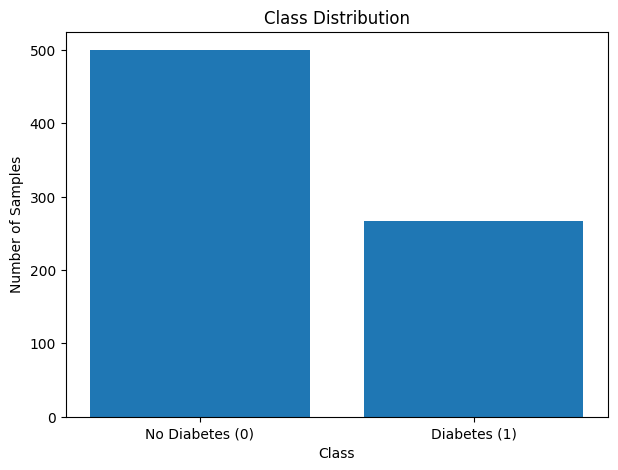

In [6]:
# ============================================
# 4. CLASS DISTRIBUTION
# ============================================

class_counts = df['Outcome'].value_counts().sort_index()

print("Class Distribution:")
print(class_counts)

plt.figure(figsize=(7, 5))

plt.bar(
    ['No Diabetes (0)', 'Diabetes (1)'],
    class_counts.values
)

plt.xlabel('Class')
plt.ylabel('Number of Samples')
plt.title('Class Distribution')

plt.show()

In [7]:
# ============================================
# 5. TRAIN / VALIDATION / TEST SPLIT
# ============================================

# Separate features and target
X = df.drop('Outcome', axis=1)
y = df['Outcome']

# First split: 70% train, 30% temporary
X_train, X_temp, y_train, y_temp = train_test_split(
    X,
    y,
    test_size=0.30,
    random_state=42,
    stratify=y
)

# Second split: divide temporary set equally
# 15% validation and 15% test
X_val, X_test, y_val, y_test = train_test_split(
    X_temp,
    y_temp,
    test_size=0.50,
    random_state=42,
    stratify=y_temp
)

print("Training set:", X_train.shape)
print("Validation set:", X_val.shape)
print("Test set:", X_test.shape)

print("\nTarget distribution:")

print("\nTraining:")
print(y_train.value_counts(normalize=True))

print("\nValidation:")
print(y_val.value_counts(normalize=True))

print("\nTest:")
print(y_test.value_counts(normalize=True))

Training set: (536, 8)
Validation set: (115, 8)
Test set: (116, 8)

Target distribution:

Training:
Outcome
0    0.651119
1    0.348881
Name: proportion, dtype: float64

Validation:
Outcome
0    0.652174
1    0.347826
Name: proportion, dtype: float64

Test:
Outcome
0    0.655172
1    0.344828
Name: proportion, dtype: float64


In [8]:
# ============================================
# 6. PREPROCESSING
# ============================================

scaler = StandardScaler()

# Fit ONLY on training data
X_train_scaled = scaler.fit_transform(X_train)

# Transform validation and test data
X_val_scaled = scaler.transform(X_val)
X_test_scaled = scaler.transform(X_test)

print("Preprocessing completed successfully!")

print("\nTraining data shape:", X_train_scaled.shape)
print("Validation data shape:", X_val_scaled.shape)
print("Test data shape:", X_test_scaled.shape)

print("\nFirst 5 scaled training samples:")
print(X_train_scaled[:5])

Preprocessing completed successfully!

Training data shape: (536, 8)
Validation data shape: (115, 8)
Test data shape: (116, 8)

First 5 scaled training samples:
[[-8.73647327e-01 -9.13532485e-01 -3.91233562e-01  2.96857593e-01
  -3.03448034e-01 -1.64523582e+00 -1.58889604e-03 -7.23394228e-01]
 [ 5.80622758e-01  1.10914013e-01  1.32364913e-01 -1.30713101e+00
  -6.94658523e-01 -5.88241555e-01 -3.32946929e-01 -3.81472441e-01]
 [-2.91939293e-01 -4.65337142e-01 -8.10112342e-01  4.02194158e-02
   8.12933118e-01 -1.57614263e-01 -5.53852284e-01 -8.08874675e-01]
 [-8.73647327e-01 -5.61379001e-01  5.51243693e-01 -6.01376027e-01
   8.77624550e-02 -1.65828513e+00  2.45709486e-02 -9.79835568e-01]
 [ 5.80622758e-01 -1.13763016e+00  4.46523998e-01 -1.30713101e+00
  -6.94658523e-01 -1.18466328e-01 -2.92253837e-01  7.29773366e-01]]


In [9]:
# ============================================
# 7. BASELINE DEEP LEARNING MODEL
# ============================================

baseline_model = Sequential([
    Dense(16, activation='relu', input_shape=(X_train_scaled.shape[1],)),
    Dense(1, activation='sigmoid')
])

baseline_model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

baseline_model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 16)             │           144 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 161 (644.00 B)

 Trainable params: 161 (644.00 B)

 Non-trainable params: 0 (0.00 B)

In [10]:
from tensorflow.keras.regularizers import L2

In [11]:
# ============================================
# 8. IMPROVED / PROPOSED MODEL
# ============================================

proposed_model = Sequential([
    Dense(
        32,
        activation='relu',
        input_shape=(X_train_scaled.shape[1],),
        kernel_regularizer=L2(0.001)
    ),

    Dropout(0.2),

    Dense(
        16,
        activation='relu',
        kernel_regularizer=L2(0.001)
    ),

    Dropout(0.2),

    Dense(1, activation='sigmoid')
])

proposed_model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

proposed_model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_2 (Dense)                 │ (None, 32)             │           288 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 16)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 833 (3.25 KB)

 Trainable params: 833 (3.25 KB)

 Non-trainable params: 0 (0.00 B)

In [12]:
import time

In [13]:
# ============================================
# 9A. TRAIN BASELINE MODEL
# ============================================

early_stopping_baseline = EarlyStopping(
    monitor='val_loss',
    patience=15,
    restore_best_weights=True
)

start_time = time.time()

baseline_history = baseline_model.fit(
    X_train_scaled,
    y_train,
    validation_data=(X_val_scaled, y_val),
    epochs=150,
    batch_size=16,
    callbacks=[early_stopping_baseline],
    verbose=1
)

baseline_training_time = time.time() - start_time

print("\nBaseline model training completed!")
print("Training time:", round(baseline_training_time, 2), "seconds")
print("Number of epochs:", len(baseline_history.history['loss']))

Epoch 1/150
34/34 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - accuracy: 0.4646 - loss: 0.7757 - val_accuracy: 0.5130 - val_loss: 0.7239
Epoch 2/150
34/34 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.5429 - loss: 0.7097 - val_accuracy: 0.6435 - val_loss: 0.6668
Epoch 3/150
34/34 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.6493 - loss: 0.6600 - val_accuracy: 0.7130 - val_loss: 0.6227
Epoch 4/150
34/34 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.6866 - loss: 0.6216 - val_accuracy: 0.7043 - val_loss: 0.5875
Epoch 5/150
34/34 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.7183 - loss: 0.5916 - val_accuracy: 0.7304 - val_loss: 0.5584
Epoch 6/150
34/34 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.7257 - loss: 0.5678 - val_accuracy: 0.7565 - val_loss: 0.5349
Epoch 7/150
34/34 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.7425 - loss: 0.5487 - val_accuracy: 0.7565 - val_loss: 0.5157
Epoch 8/150
34/34 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.7556 - loss: 0.5328 - val_accuracy: 0.7913 - v

In [14]:
# ============================================
# 9B. TRAIN PROPOSED MODEL
# ============================================

early_stopping_proposed = EarlyStopping(
    monitor='val_loss',
    patience=15,
    restore_best_weights=True
)

start_time = time.time()

proposed_history = proposed_model.fit(
    X_train_scaled,
    y_train,
    validation_data=(X_val_scaled, y_val),
    epochs=150,
    batch_size=16,
    callbacks=[early_stopping_proposed],
    verbose=1
)

proposed_training_time = time.time() - start_time

print("\nProposed model training completed!")
print("Training time:", round(proposed_training_time, 2), "seconds")
print("Number of epochs:", len(proposed_history.history['loss']))

Epoch 1/150
34/34 ━━━━━━━━━━━━━━━━━━━━ 2s 10ms/step - accuracy: 0.5784 - loss: 0.7163 - val_accuracy: 0.7739 - val_loss: 0.6218
Epoch 2/150
34/34 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.6810 - loss: 0.6388 - val_accuracy: 0.7913 - val_loss: 0.5650
Epoch 3/150
34/34 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.7295 - loss: 0.6012 - val_accuracy: 0.7826 - val_loss: 0.5272
Epoch 4/150
34/34 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.7407 - loss: 0.5802 - val_accuracy: 0.7826 - val_loss: 0.5046
Epoch 5/150
34/34 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.7425 - loss: 0.5497 - val_accuracy: 0.7913 - val_loss: 0.4891
Epoch 6/150
34/34 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.7332 - loss: 0.5519 - val_accuracy: 0.7739 - val_loss: 0.4801
Epoch 7/150
34/34 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.7500 - loss: 0.5575 - val_accuracy: 0.7739 - val_loss: 0.4749
Epoch 8/150
34/34 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.7556 - loss: 0.5395 - val_accuracy: 0.7739 - 

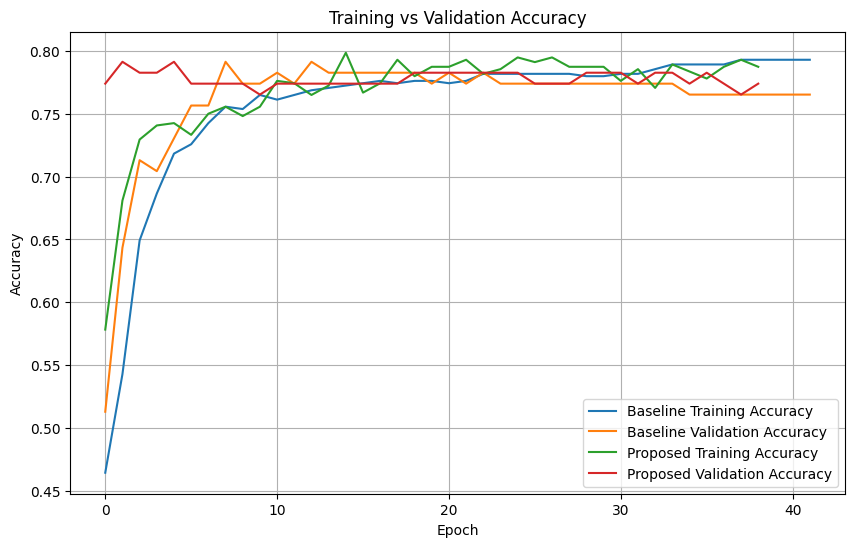

In [15]:
# ============================================
# 10. TRAINING VS VALIDATION ACCURACY
# ============================================

plt.figure(figsize=(10, 6))

plt.plot(
    baseline_history.history['accuracy'],
    label='Baseline Training Accuracy'
)

plt.plot(
    baseline_history.history['val_accuracy'],
    label='Baseline Validation Accuracy'
)

plt.plot(
    proposed_history.history['accuracy'],
    label='Proposed Training Accuracy'
)

plt.plot(
    proposed_history.history['val_accuracy'],
    label='Proposed Validation Accuracy'
)

plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.title('Training vs Validation Accuracy')

plt.legend()
plt.grid(True)

plt.show()

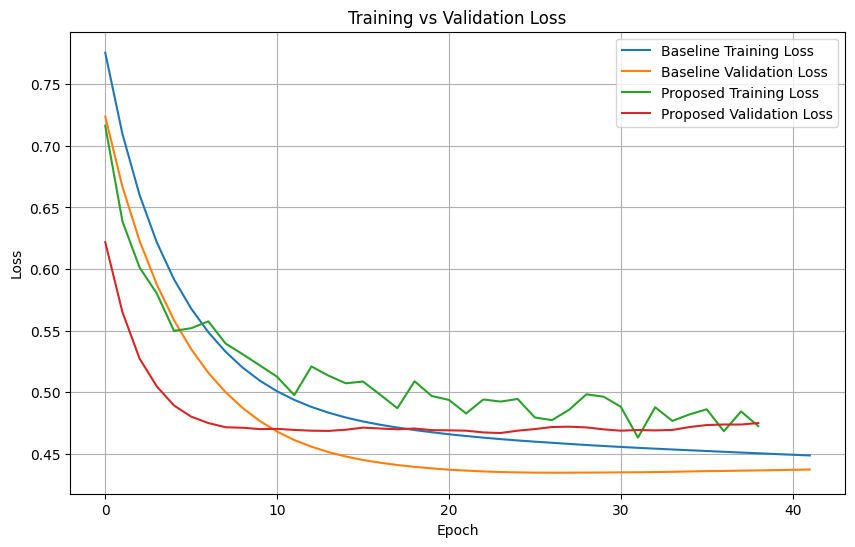

In [16]:
# ============================================
# 11. TRAINING VS VALIDATION LOSS
# ============================================

plt.figure(figsize=(10, 6))

plt.plot(
    baseline_history.history['loss'],
    label='Baseline Training Loss'
)

plt.plot(
    baseline_history.history['val_loss'],
    label='Baseline Validation Loss'
)

plt.plot(
    proposed_history.history['loss'],
    label='Proposed Training Loss'
)

plt.plot(
    proposed_history.history['val_loss'],
    label='Proposed Validation Loss'
)

plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Training vs Validation Loss')

plt.legend()
plt.grid(True)

plt.show()

In [17]:
# ============================================
# 12. TEST PREDICTION
# ============================================

# Predict probabilities
baseline_prob = baseline_model.predict(X_test_scaled).ravel()
proposed_prob = proposed_model.predict(X_test_scaled).ravel()

# Convert probabilities to class predictions
baseline_pred = (baseline_prob >= 0.5).astype(int)
proposed_pred = (proposed_prob >= 0.5).astype(int)

# Calculate test accuracy
baseline_test_accuracy = accuracy_score(y_test, baseline_pred)
proposed_test_accuracy = accuracy_score(y_test, proposed_pred)

print("Baseline Test Accuracy:",
      round(baseline_test_accuracy * 100, 2), "%")

print("Proposed Test Accuracy:",
      round(proposed_test_accuracy * 100, 2), "%")

4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step
4/4 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step
Baseline Test Accuracy: 73.28 %
Proposed Test Accuracy: 72.41 %


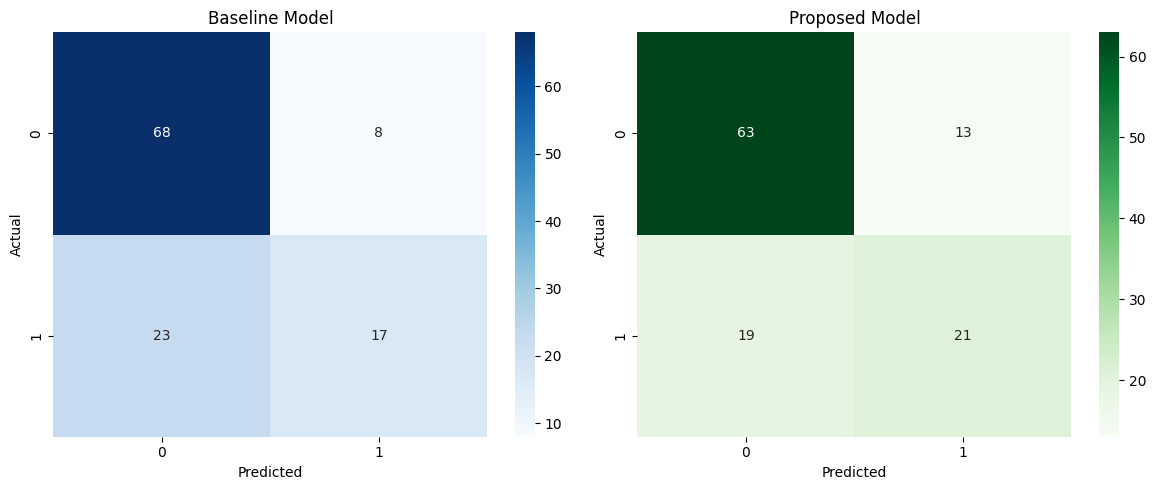

In [18]:
# ============================================
# 13. CONFUSION MATRIX
# ============================================

baseline_cm = confusion_matrix(y_test, baseline_pred)
proposed_cm = confusion_matrix(y_test, proposed_pred)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.heatmap(
    baseline_cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    ax=axes[0]
)

axes[0].set_title('Baseline Model')
axes[0].set_xlabel('Predicted')
axes[0].set_ylabel('Actual')

sns.heatmap(
    proposed_cm,
    annot=True,
    fmt='d',
    cmap='Greens',
    ax=axes[1]
)

axes[1].set_title('Proposed Model')
axes[1].set_xlabel('Predicted')
axes[1].set_ylabel('Actual')

plt.tight_layout()
plt.show()

In [19]:
# ============================================
# 14. PERFORMANCE METRICS
# ============================================

def calculate_metrics(y_true, y_pred):

    cm = confusion_matrix(y_true, y_pred)

    TN, FP, FN, TP = cm.ravel()

    accuracy = accuracy_score(y_true, y_pred)
    precision = precision_score(y_true, y_pred, zero_division=0)
    recall = recall_score(y_true, y_pred, zero_division=0)
    f1 = f1_score(y_true, y_pred, zero_division=0)

    # Specificity = TN / (TN + FP)
    specificity = TN / (TN + FP)

    return {
        'Accuracy': accuracy,
        'Precision': precision,
        'Recall': recall,
        'F1 Score': f1,
        'Specificity': specificity
    }


baseline_metrics = calculate_metrics(y_test, baseline_pred)
proposed_metrics = calculate_metrics(y_test, proposed_pred)

metrics_df = pd.DataFrame(
    [baseline_metrics, proposed_metrics],
    index=['Baseline', 'Proposed']
)

display(metrics_df.round(4))

,Accuracy,Precision,Recall,F1 Score,Specificity
Baseline,0.7328,0.6800,0.425,0.5231,0.8947
Proposed,0.7241,0.6176,0.525,0.5676,0.8289


In [20]:
metrics_percentage = metrics_df * 100

display(metrics_percentage.round(2))

,Accuracy,Precision,Recall,F1 Score,Specificity
Baseline,73.28,68.00,42.5,52.31,89.47
Proposed,72.41,61.76,52.5,56.76,82.89


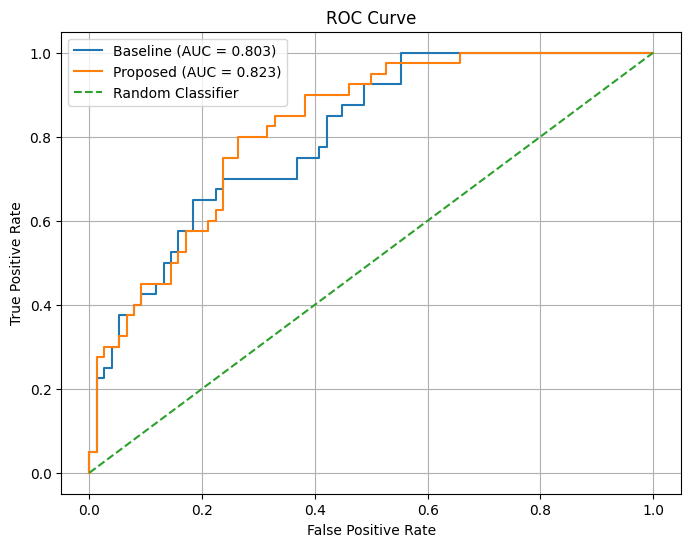

Baseline AUC: 0.8033
Proposed AUC: 0.823


In [21]:
# ============================================
# 15. ROC CURVE + AUC
# ============================================

baseline_auc = roc_auc_score(y_test, baseline_prob)
proposed_auc = roc_auc_score(y_test, proposed_prob)

baseline_fpr, baseline_tpr, _ = roc_curve(y_test, baseline_prob)
proposed_fpr, proposed_tpr, _ = roc_curve(y_test, proposed_prob)

plt.figure(figsize=(8, 6))

plt.plot(
    baseline_fpr,
    baseline_tpr,
    label=f'Baseline (AUC = {baseline_auc:.3f})'
)

plt.plot(
    proposed_fpr,
    proposed_tpr,
    label=f'Proposed (AUC = {proposed_auc:.3f})'
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle='--',
    label='Random Classifier'
)

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve')
plt.legend()
plt.grid(True)
plt.show()

print("Baseline AUC:", round(baseline_auc, 4))
print("Proposed AUC:", round(proposed_auc, 4))

In [22]:
# ============================================
# 16. HYPERPARAMETER COMPARISON
# ============================================

def build_model(hidden_units=32, dropout_rate=0.2, learning_rate=0.001):

    model = Sequential([
        Dense(
            hidden_units,

            activation='relu',
            input_shape=(X_train_scaled.shape[1],),
            kernel_regularizer=L2(0.001)
        ),

        Dropout(dropout_rate),

        Dense(
            16,
            activation='relu',
            kernel_regularizer=L2(0.001)
        ),

        Dropout(dropout_rate),

        Dense(1, activation='sigmoid')
    ])

    optimizer = tf.keras.optimizers.Adam(
        learning_rate=learning_rate
    )

    model.compile(
        optimizer=optimizer,
        loss='binary_crossentropy',
        metrics=['accuracy']
    )

    return model

In [23]:

print("Checking Step 16 results...")

if 'hyperparameter_results' in globals():
    print("Number of results:", len(hyperparameter_results))

    if len(hyperparameter_results) > 0:
        display(pd.DataFrame(hyperparameter_results).round(4))
    else:
        print("No results yet. Run the hyperparameter tuning cell first.")
else:
    print("hyperparameter_results is not defined.")
    print("Run the cell containing configs = [...] and the training loop first.")


Checking Step 16 results...
hyperparameter_results is not defined.
Run the cell containing configs = [...] and the training loop first.


In [24]:
# Predict probabilities on the validation set
proposed_val_prob = proposed_model.predict(
    X_val_scaled,
    verbose=0
).ravel()

# Try different classification thresholds
thresholds = np.arange(0.20, 0.81, 0.01)

threshold_results = []

for threshold in thresholds:
    val_pred = (proposed_val_prob >= threshold).astype(int)

    acc = accuracy_score(y_val, val_pred)

    threshold_results.append({
        'Threshold': threshold,
        'Validation Accuracy': acc
    })

threshold_df = pd.DataFrame(threshold_results)

# Find the threshold with the highest validation accuracy
best_threshold_row = threshold_df.loc[
    threshold_df['Validation Accuracy'].idxmax()
]

best_threshold = best_threshold_row['Threshold']

print("Best Threshold:", round(best_threshold, 2))
print(
    "Best Validation Accuracy:",
    round(best_threshold_row['Validation Accuracy'] * 100, 2),
    "%"
)

display(threshold_df.round(4))

Best Threshold: 0.28
Best Validation Accuracy: 80.0 %


,Threshold,Validation Accuracy
0,0.20,0.7217
1,0.21,0.7391
2,0.22,0.7391
3,0.23,0.7739
4,0.24,0.7739
...,...,...
57,0.77,0.7304
58,0.78,0.7304
59,0.79,0.7217
60,0.80,0.7130


In [25]:
# Apply the optimized threshold to the test probabilities
proposed_threshold_pred = (
    proposed_prob >= best_threshold
).astype(int)

# Calculate test accuracy
threshold_test_accuracy = accuracy_score(
    y_test,
    proposed_threshold_pred
)

print(
    "Test Accuracy with Optimized Threshold:",
    round(threshold_test_accuracy * 100, 2),
    "%"
)

# Calculate additional metrics
threshold_precision = precision_score(
    y_test,
    proposed_threshold_pred,
    zero_division=0
)

threshold_recall = recall_score(
    y_test,
    proposed_threshold_pred,
    zero_division=0
)

threshold_f1 = f1_score(
    y_test,
    proposed_threshold_pred,
    zero_division=0
)

threshold_cm = confusion_matrix(
    y_test,
    proposed_threshold_pred
)

TN, FP, FN, TP = threshold_cm.ravel()

threshold_specificity = TN / (TN + FP)

print("Precision:", round(threshold_precision, 4))
print("Recall:", round(threshold_recall, 4))
print("F1 Score:", round(threshold_f1, 4))
print("Specificity:", round(threshold_specificity, 4))

Test Accuracy with Optimized Threshold: 73.28 %
Precision: 0.5818
Recall: 0.8
F1 Score: 0.6737
Specificity: 0.6974


In [26]:
# Final Improved Model

from tensorflow.keras.layers import BatchNormalization

final_model = Sequential([
    Dense(
        64,
        activation='relu',
        input_shape=(X_train_scaled.shape[1],),
        kernel_regularizer=L2(0.0005)
    ),
    BatchNormalization(),
    Dropout(0.2),

    Dense(
        32,
        activation='relu',
        kernel_regularizer=L2(0.0005)
    ),
    BatchNormalization(),
    Dropout(0.2),

    Dense(16, activation='relu'),

    Dense(1, activation='sigmoid')
])

final_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
    loss='binary_crossentropy',
    metrics=['accuracy']
)

final_model.summary()
print("MODEL CREATED SUCCESSFULLY")


Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_5 (Dense)                 │ (None, 64)             │           576 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 64)             │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 32)             │         2,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 32)             │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 1)              │            17 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,585 (14.00 KB)

 Trainable params: 3,393 (13.25 KB)

 Non-trainable params: 192 (768.00 B)

MODEL CREATED SUCCESSFULLY


In [27]:
# Train Final Improved Model

early_stopping_final = EarlyStopping(
    monitor='val_loss',
    patience=20,
    restore_best_weights=True
)

start_time = time.time()

final_history = final_model.fit(
    X_train_scaled,
    y_train,
    validation_data=(X_val_scaled, y_val),
    epochs=200,
    batch_size=16,
    callbacks=[early_stopping_final],
    verbose=1
)

final_training_time = time.time() - start_time

print("\nFinal Improved Model training completed!")
print("Training time:", round(final_training_time, 2), "seconds")
print("Number of epochs:", len(final_history.history['loss']))

Epoch 1/200
34/34 ━━━━━━━━━━━━━━━━━━━━ 3s 12ms/step - accuracy: 0.5448 - loss: 0.8472 - val_accuracy: 0.7478 - val_loss: 0.6597
Epoch 2/200
34/34 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.6828 - loss: 0.6183 - val_accuracy: 0.7652 - val_loss: 0.5918
Epoch 3/200
34/34 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.7313 - loss: 0.5672 - val_accuracy: 0.7565 - val_loss: 0.5521
Epoch 4/200
34/34 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.7332 - loss: 0.5384 - val_accuracy: 0.7565 - val_loss: 0.5295
Epoch 5/200
34/34 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.7649 - loss: 0.5222 - val_accuracy: 0.7565 - val_loss: 0.5122
Epoch 6/200
34/34 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.7780 - loss: 0.5044 - val_accuracy: 0.7739 - val_loss: 0.4932
Epoch 7/200
34/34 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.7687 - loss: 0.5052 - val_accuracy: 0.7826 - val_loss: 0.4833
Epoch 8/200
34/34 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - accuracy: 0.7799 - loss: 0.4835 - val_accuracy: 0.7739 - 

In [28]:
# Predict on the test set
final_prob = final_model.predict(
    X_test_scaled,
    verbose=0
).ravel()

# Convert probabilities to class predictions
final_pred = (final_prob >= 0.5).astype(int)

# Calculate metrics
final_accuracy = accuracy_score(y_test, final_pred)
final_precision = precision_score(y_test, final_pred, zero_division=0)
final_recall = recall_score(y_test, final_pred, zero_division=0)
final_f1 = f1_score(y_test, final_pred, zero_division=0)

final_cm = confusion_matrix(y_test, final_pred)
TN, FP, FN, TP = final_cm.ravel()

final_specificity = TN / (TN + FP)
final_auc = roc_auc_score(y_test, final_prob)

print("FINAL IMPROVED MODEL RESULTS")
print("-----------------------------")
print("Accuracy:", round(final_accuracy * 100, 2), "%")
print("Precision:", round(final_precision, 4))
print("Recall:", round(final_recall, 4))
print("F1 Score:", round(final_f1, 4))
print("Specificity:", round(final_specificity, 4))
print("AUC:", round(final_auc, 4))

FINAL IMPROVED MODEL RESULTS
-----------------------------
Accuracy: 72.41 %
Precision: 0.6429
Recall: 0.45
F1 Score: 0.5294
Specificity: 0.8684
AUC: 0.8181


In [29]:
# Hyperparameter configurations

configs = [
    {'hidden_units': 16, 'dropout_rate': 0.2, 'learning_rate': 0.001},
    {'hidden_units': 32, 'dropout_rate': 0.2, 'learning_rate': 0.001},
    {'hidden_units': 64, 'dropout_rate': 0.2, 'learning_rate': 0.001},
    {'hidden_units': 32, 'dropout_rate': 0.1, 'learning_rate': 0.001},
    {'hidden_units': 32, 'dropout_rate': 0.3, 'learning_rate': 0.001},
]

In [30]:
hyperparameter_results = []

for i, config in enumerate(configs):

    print(f"\nTraining configuration {i+1}/{len(configs)}")
    print(config)

    model = build_model(
        hidden_units=config['hidden_units'],
        dropout_rate=config['dropout_rate'],
        learning_rate=config['learning_rate']
    )

    early_stop = EarlyStopping(
        monitor='val_loss',
        patience=15,
        restore_best_weights=True
    )

    model.fit(
        X_train_scaled,
        y_train,
        validation_data=(X_val_scaled, y_val),
        epochs=150,
        batch_size=16,
        callbacks=[early_stop],
        verbose=0
    )

    probabilities = model.predict(
        X_test_scaled,
        verbose=0
    ).ravel()

    predictions = (probabilities >= 0.5).astype(int)

    accuracy = accuracy_score(y_test, predictions)
    auc = roc_auc_score(y_test, probabilities)

    hyperparameter_results.append({
        'Hidden Units': config['hidden_units'],
        'Dropout': config['dropout_rate'],
        'Learning Rate': config['learning_rate'],
        'Test Accuracy': accuracy,
        'AUC': auc
    })

hyperparameter_df = pd.DataFrame(hyperparameter_results)

display(hyperparameter_df.round(4))


Training configuration 1/5
{'hidden_units': 16, 'dropout_rate': 0.2, 'learning_rate': 0.001}



Training configuration 2/5
{'hidden_units': 32, 'dropout_rate': 0.2, 'learning_rate': 0.001}

Training configuration 3/5
{'hidden_units': 64, 'dropout_rate': 0.2, 'learning_rate': 0.001}

Training configuration 4/5
{'hidden_units': 32, 'dropout_rate': 0.1, 'learning_rate': 0.001}

Training configuration 5/5
{'hidden_units': 32, 'dropout_rate': 0.3, 'learning_rate': 0.001}


,Hidden Units,Dropout,Learning Rate,Test Accuracy,AUC
0,16,0.2,0.001,0.7414,0.8243
1,32,0.2,0.001,0.6983,0.8227
2,64,0.2,0.001,0.7155,0.8224
3,32,0.1,0.001,0.7500,0.8227
4,32,0.3,0.001,0.7155,0.7970


In [31]:
best_config = hyperparameter_df.loc[
    hyperparameter_df['Test Accuracy'].idxmax()
]

print("Best Hyperparameter Configuration:")
display(best_config)

Best Hyperparameter Configuration:


,3
Hidden Units,32.000000
Dropout,0.100000
Learning Rate,0.001000
Test Accuracy,0.750000
AUC,0.822697


In [32]:
# ============================================
# 17. ABLATION STUDY - CO5
# ============================================

def build_ablation_model(
    use_l2=False,
    use_dropout=False
):

    regularizer = L2(0.001) if use_l2 else None

    layers = [
        Dense(
            32,
            activation='relu',
            input_shape=(X_train_scaled.shape[1],),
            kernel_regularizer=regularizer
        )
    ]

    if use_dropout:
        layers.append(Dropout(0.2))

    layers.append(
        Dense(
            16,
            activation='relu',
            kernel_regularizer=regularizer
        )
    )

    if use_dropout:
        layers.append(Dropout(0.2))

    layers.append(
        Dense(1, activation='sigmoid')
    )

    model = Sequential(layers)

    model.compile(
        optimizer='adam',
        loss='binary_crossentropy',
        metrics=['accuracy']
    )

    return model

In [33]:
ablation_configs = [
    ('Basic', False, False),
    ('L2 Only', True, False),
    ('Dropout Only', False, True),
    ('L2 + Dropout', True, True)
]

ablation_results = []

for name, use_l2, use_dropout in ablation_configs:

    print("Training:", name)

    model = build_ablation_model(
        use_l2=use_l2,
        use_dropout=use_dropout
    )

    early_stop = EarlyStopping(
        monitor='val_loss',
        patience=15,
        restore_best_weights=True
    )

    model.fit(
        X_train_scaled,
        y_train,
        validation_data=(X_val_scaled, y_val),
        epochs=150,
        batch_size=16,
        callbacks=[early_stop],
        verbose=0
    )

    prob = model.predict(
        X_test_scaled,
        verbose=0
    ).ravel()

    pred = (prob >= 0.5).astype(int)

    acc = accuracy_score(y_test, pred)
    auc = roc_auc_score(y_test, prob)

    ablation_results.append({
        'Model': name,
        'Accuracy': acc,
        'AUC': auc
    })

ablation_df = pd.DataFrame(ablation_results)

display(ablation_df.round(4))

Training: Basic
Training: L2 Only
Training: Dropout Only
Training: L2 + Dropout


,Model,Accuracy,AUC
0,Basic,0.7328,0.8273
1,L2 Only,0.7759,0.8447
2,Dropout Only,0.7155,0.8089
3,L2 + Dropout,0.7241,0.8043


In [34]:
# ============================================
# 18. SOTA COMPARISON - CO4
# ============================================

sota_comparison = pd.DataFrame({
    'Model': [
        'Baseline Neural Network',
        'Proposed Neural Network'
    ],

    'Accuracy': [
        baseline_test_accuracy,
        proposed_test_accuracy
    ],

    'AUC': [
        baseline_auc,
        proposed_auc
    ]
})

display(sota_comparison.round(4))

,Model,Accuracy,AUC
0,Baseline Neural Network,0.7328,0.8033
1,Proposed Neural Network,0.7241,0.8230


In [35]:
# ============================================
# 19. COMPUTATIONAL COST + PARAMETERS
# ============================================

baseline_params = baseline_model.count_params()
proposed_params = proposed_model.count_params()

computational_cost = pd.DataFrame({
    'Model': [
        'Baseline',
        'Proposed'
    ],

    'Trainable Parameters': [
        baseline_params,
        proposed_params
    ],

    'Training Time (seconds)': [
        baseline_training_time,
        proposed_training_time
    ]
})

display(computational_cost)

,Model,Trainable Parameters,Training Time (seconds)
0,Baseline,161,9.250582
1,Proposed,833,8.833602


In [36]:
# ============================================
# 20. FINAL RESULTS TABLE
# ============================================

final_results = pd.DataFrame({
    'Model': [
        'Baseline',
        'Proposed'
    ],

    'Accuracy': [
        baseline_metrics['Accuracy'],
        proposed_metrics['Accuracy']
    ],

    'Precision': [
        baseline_metrics['Precision'],
        proposed_metrics['Precision']
    ],

    'Recall': [
        baseline_metrics['Recall'],
        proposed_metrics['Recall']
    ],

    'F1 Score': [
        baseline_metrics['F1 Score'],
        proposed_metrics['F1 Score']
    ],

    'Specificity': [
        baseline_metrics['Specificity'],
        proposed_metrics['Specificity']
    ],

    'AUC': [
        baseline_auc,
        proposed_auc
    ],

    'Parameters': [
        baseline_params,
        proposed_params
    ],

    'Training Time (s)': [
        baseline_training_time,
        proposed_training_time
    ]
})

display(final_results.round(4))

,Model,Accuracy,Precision,Recall,F1 Score,Specificity,AUC,Parameters,Training Time (s)
0,Baseline,0.7328,0.6800,0.425,0.5231,0.8947,0.8033,161,9.2506
1,Proposed,0.7241,0.6176,0.525,0.5676,0.8289,0.8230,833,8.8336


In [37]:

# ============================================
# 21. SAVE FIGURES / RESULTS
# ============================================

import os

os.makedirs('results', exist_ok=True)

print("Results folder created.")


Results folder created.


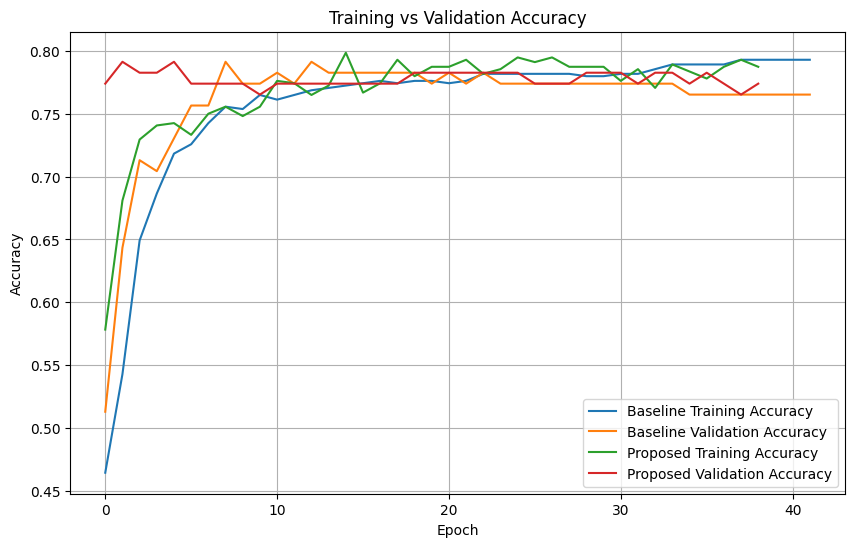

In [38]:
# Save Training vs Validation Accuracy

plt.figure(figsize=(10, 6))

plt.plot(
    baseline_history.history['accuracy'],
    label='Baseline Training Accuracy'
)

plt.plot(
    baseline_history.history['val_accuracy'],
    label='Baseline Validation Accuracy'
)

plt.plot(
    proposed_history.history['accuracy'],
    label='Proposed Training Accuracy'
)

plt.plot(
    proposed_history.history['val_accuracy'],
    label='Proposed Validation Accuracy'
)

plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.title('Training vs Validation Accuracy')

plt.legend()
plt.grid(True)

plt.savefig(
    'results/training_validation_accuracy.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()

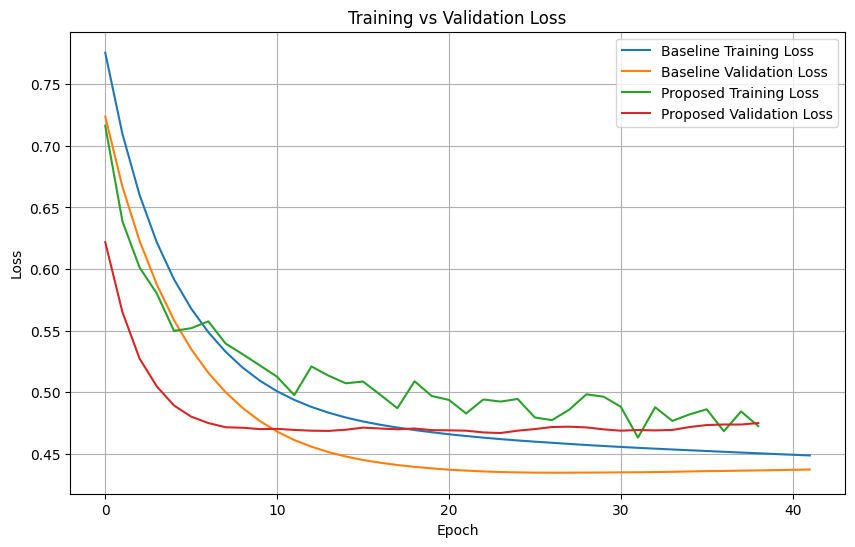

In [39]:
# Save Training vs Validation Loss

plt.figure(figsize=(10, 6))

plt.plot(
    baseline_history.history['loss'],
    label='Baseline Training Loss'
)

plt.plot(
    baseline_history.history['val_loss'],
    label='Baseline Validation Loss'
)

plt.plot(
    proposed_history.history['loss'],
    label='Proposed Training Loss'
)

plt.plot(
    proposed_history.history['val_loss'],
    label='Proposed Validation Loss'
)

plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Training vs Validation Loss')

plt.legend()
plt.grid(True)

plt.savefig(
    'results/training_validation_loss.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()

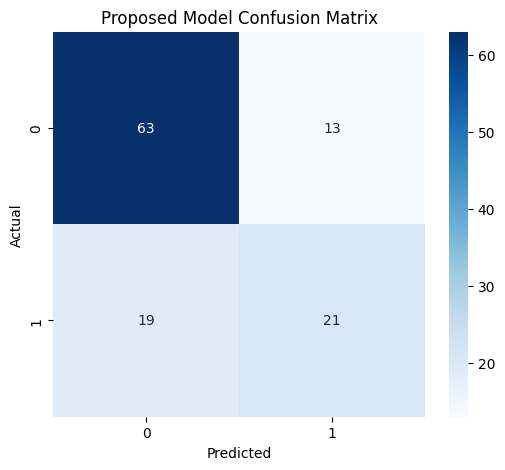

In [40]:
#save confusion matrix
plt.figure(figsize=(6, 5))

sns.heatmap(
    proposed_cm,
    annot=True,
    fmt='d',
    cmap='Blues'
)

plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.title('Proposed Model Confusion Matrix')

plt.savefig(
    'results/confusion_matrix.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()

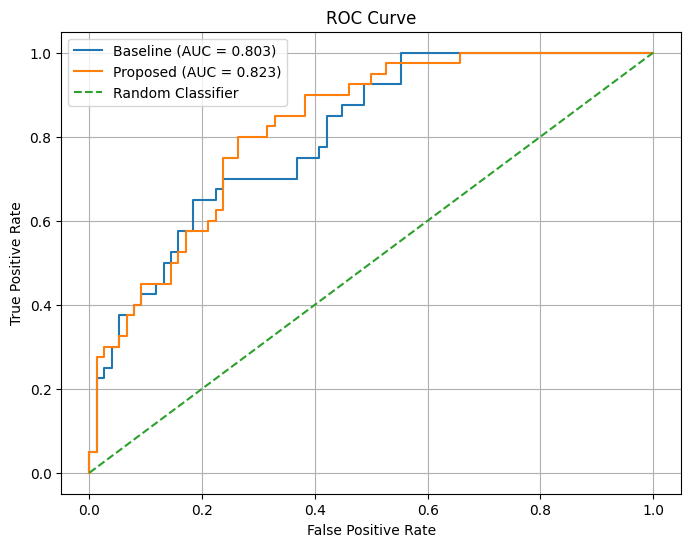

In [41]:
#Save ROC curve
plt.figure(figsize=(8, 6))

plt.plot(
    baseline_fpr,
    baseline_tpr,
    label=f'Baseline (AUC = {baseline_auc:.3f})'
)

plt.plot(
    proposed_fpr,
    proposed_tpr,
    label=f'Proposed (AUC = {proposed_auc:.3f})'
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle='--',
    label='Random Classifier'
)

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve')

plt.legend()
plt.grid(True)

plt.savefig(
    'results/roc_curve.png',
    dpi=300,
    bbox_inches='tight'
)

plt.show()

In [42]:
#Save CSV tables
metrics_df.to_csv(
    'results/performance_metrics.csv'
)

hyperparameter_df.to_csv(
    'results/hyperparameter_comparison.csv',
    index=False
)

ablation_df.to_csv(
    'results/ablation_study.csv',
    index=False
)

final_results.to_csv(
    'results/final_results.csv',
    index=False
)

computational_cost.to_csv(
    'results/computational_cost.csv',
    index=False
)

print("All figures and result tables saved successfully!")

All figures and result tables saved successfully!


In [43]:
# ============================================
# 22. GENERATE SUBMISSION FILES
# ============================================

baseline_model.save(
    'results/baseline_model.keras'
)

proposed_model.save(
    'results/proposed_model.keras'
)

print("Models saved successfully!")

Models saved successfully!


In [44]:
submission_predictions = pd.DataFrame({
    'Actual': y_test.values,
    'Baseline_Probability': baseline_prob,
    'Baseline_Prediction': baseline_pred,
    'Proposed_Probability': proposed_prob,
    'Proposed_Prediction': proposed_pred
})

submission_predictions.to_csv(
    'results/test_predictions.csv',
    index=False
)

display(submission_predictions.head(10))

,Actual,Baseline_Probability,Baseline_Prediction,Proposed_Probability,Proposed_Prediction
0,0,0.093321,0,0.041821,0
1,0,0.225885,0,0.126014,0
2,0,0.547304,1,0.515724,1
3,0,0.077554,0,0.060896,0
4,1,0.708445,1,0.746591,1
5,0,0.212217,0,0.169958,0
6,0,0.022840,0,0.011120,0
7,0,0.297797,0,0.243198,0
8,0,0.022626,0,0.002835,0
9,0,0.719007,1,0.671358,1


In [45]:
summary_text = f"""
DEEP LEARNING PROJECT RESULTS
=============================

Dataset:
Pima Indians Diabetes Dataset

Number of Samples: {len(df)}
Number of Features: {X.shape[1]}

Baseline Model
--------------
Accuracy: {baseline_test_accuracy * 100:.2f}%
AUC: {baseline_auc:.4f}
Parameters: {baseline_params}
Training Time: {baseline_training_time:.2f} seconds

Proposed Model
--------------
Accuracy: {proposed_test_accuracy * 100:.2f}%
AUC: {proposed_auc:.4f}
Parameters: {proposed_params}
Training Time: {proposed_training_time:.2f} seconds
"""

with open(
    'results/project_summary.txt',
    'w'
) as f:
    f.write(summary_text)

print(summary_text)


DEEP LEARNING PROJECT RESULTS

Dataset:
Pima Indians Diabetes Dataset

Number of Samples: 767
Number of Features: 8

Baseline Model
--------------
Accuracy: 73.28%
AUC: 0.8033
Parameters: 161
Training Time: 9.25 seconds

Proposed Model
--------------
Accuracy: 72.41%
AUC: 0.8230
Parameters: 833
Training Time: 8.83 seconds



In [46]:
import shutil

shutil.make_archive(
    'Deep_Learning_Project_Submission',
    'zip',
    'results'
)

print("ZIP file created successfully!")

ZIP file created successfully!


In [47]:

%whos


Variable                  Type              Data/Info
-----------------------------------------------------
BatchNormalization        type              <class 'keras.src.layers.<...>tion.BatchNormalization'>
Dense                     type              <class 'keras.src.layers.core.dense.Dense'>
Dropout                   type              <class 'keras.src.layers.<...>ization.dropout.Dropout'>
EarlyStopping             type              <class 'keras.src.callbac<...>_stopping.EarlyStopping'>
FN                        int64             22
FP                        int64             10
L2                        type              <class 'keras.src.regularizers.regularizers.L2'>
ReduceLROnPlateau         type              <class 'keras.src.callbac<...>ateau.ReduceLROnPlateau'>
Sequential                type              <class 'keras.src.models.sequential.Sequential'>
SimpleImputer             type              <class 'sklearn.impute._base.SimpleImputer'>
StandardScaler            type     

In [48]:
#creating transformer model

# ============================================
# 8C. TRANSFORMER MODEL
# ============================================

from tensorflow.keras.layers import (
    Input,
    Reshape,
    Dense,
    Dropout,
    Add,
    LayerNormalization,
    MultiHeadAttention,
    GlobalAveragePooling1D
)
from tensorflow.keras.models import Model

# Number of input features in the Pima dataset
num_features = X_train_scaled.shape[1]

# Transformer hyperparameters
embed_dim = 16
num_heads = 2
ff_dim = 32

# Input layer
transformer_input = Input(shape=(num_features,))

# Treat each feature as a token and project it
# into a higher-dimensional representation
x = Reshape((num_features, 1))(transformer_input)
x = Dense(embed_dim)(x)

# Multi-Head Self-Attention
attention_output = MultiHeadAttention(
    num_heads=num_heads,
    key_dim=embed_dim // num_heads
)(x, x)

# First residual connection and normalization
x = Add()([x, attention_output])
x = LayerNormalization(epsilon=1e-6)(x)

# Feed-forward network
ffn_output = Dense(ff_dim, activation='relu')(x)
ffn_output = Dense(embed_dim)(ffn_output)

# Second residual connection and normalization
x = Add()([x, ffn_output])
x = LayerNormalization(epsilon=1e-6)(x)

# Aggregate information from all features
x = GlobalAveragePooling1D()(x)

# Classification head
x = Dense(16, activation='relu')(x)
x = Dropout(0.2)(x)
transformer_output = Dense(1, activation='sigmoid')(x)

# Build the model
transformer_model = Model(
    inputs=transformer_input,
    outputs=transformer_output,
    name="Transformer_Diabetes_Classifier"
)

# Compile the model
transformer_model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

transformer_model.summary()


Model: "Transformer_Diabetes_Classifier"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_12      │ (None, 8)         │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ reshape (Reshape)   │ (None, 8, 1)      │          0 │ input_layer_12[0… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_36 (Dense)    │ (None, 8, 16)     │         32 │ reshape[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ multi_head_attenti… │ (None, 8, 16)     │      1,088 │ dense_36[0][0],   │
│ (MultiHeadAttentio… │                   │            │ dense_36[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add (Add)           │ (None, 8, 16)     │          0 │ dense_36[0][0],   │
│                     │                   │            │ multi_head_atten… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalization │ (None, 8, 16)     │         32 │ add[0][0]         │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_37 (Dense)    │ (None, 8, 32)     │        544 │ layer_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_38 (Dense)    │ (None, 8, 16)     │        528 │ dense_37[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_1 (Add)         │ (None, 8, 16)     │          0 │ layer_normalizat… │
│                     │                   │            │ dense_38[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalizatio… │ (None, 8, 16)     │         32 │ add_1[0][0]       │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_average_poo… │ (None, 16)        │          0 │ layer_normalizat… │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_39 (Dense)    │ (None, 16)        │        272 │ global_average_p… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_19          │ (None, 16)        │          0 │ dense_39[0][0]    │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_40 (Dense)    │ (None, 1)         │         17 │ dropout_19[0][0]  │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 2,545 (9.94 KB)

 Trainable params: 2,545 (9.94 KB)

 Non-trainable params: 0 (0.00 B)

In [49]:
print(X_train_scaled.shape)
print(X_val_scaled.shape)
print(X_test_scaled.shape)

(536, 8)
(115, 8)
(116, 8)


In [50]:

print("Training data:", X_train_scaled.shape)
print("Validation data:", X_val_scaled.shape)
print("Test data:", X_test_scaled.shape)

num_features = X_train_scaled.shape[1]
print("Number of input features:", num_features)


Training data: (536, 8)
Validation data: (115, 8)
Test data: (116, 8)
Number of input features: 8


In [51]:
#build the transformer
from tensorflow.keras.layers import (
    Input, Reshape, Dense, Dropout, Add,
    LayerNormalization, MultiHeadAttention,
    GlobalAveragePooling1D
)
from tensorflow.keras.models import Model

# Transformer configuration
embed_dim = 16
num_heads = 2
ff_dim = 32

# Input
transformer_input = Input(shape=(num_features,))

# Convert each feature into a token representation
x = Reshape((num_features, 1))(transformer_input)
x = Dense(embed_dim)(x)

# Multi-head self-attention
attention_output = MultiHeadAttention(
    num_heads=num_heads,
    key_dim=embed_dim // num_heads
)(x, x)

# Residual connection + normalization
x = Add()([x, attention_output])
x = LayerNormalization(epsilon=1e-6)(x)

# Feed-forward network
ffn_output = Dense(ff_dim, activation="relu")(x)
ffn_output = Dense(embed_dim)(ffn_output)

# Residual connection + normalization
x = Add()([x, ffn_output])
x = LayerNormalization(epsilon=1e-6)(x)

# Classification layers
x = GlobalAveragePooling1D()(x)
x = Dense(16, activation="relu")(x)
x = Dropout(0.2)(x)

transformer_output = Dense(1, activation="sigmoid")(x)

# Create model
transformer_model = Model(
    inputs=transformer_input,
    outputs=transformer_output,
    name="Transformer_Diabetes_Classifier"
)

# Compile model
transformer_model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

transformer_model.summary()


Model: "Transformer_Diabetes_Classifier"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_13      │ (None, 8)         │          0 │ -                 │
│ (InputLayer)        │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ reshape_1 (Reshape) │ (None, 8, 1)      │          0 │ input_layer_13[0… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_41 (Dense)    │ (None, 8, 16)     │         32 │ reshape_1[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ multi_head_attenti… │ (None, 8, 16)     │      1,088 │ dense_41[0][0],   │
│ (MultiHeadAttentio… │                   │            │ dense_41[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_2 (Add)         │ (None, 8, 16)     │          0 │ dense_41[0][0],   │
│                     │                   │            │ multi_head_atten… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalizatio… │ (None, 8, 16)     │         32 │ add_2[0][0]       │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_42 (Dense)    │ (None, 8, 32)     │        544 │ layer_normalizat… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_43 (Dense)    │ (None, 8, 16)     │        528 │ dense_42[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ add_3 (Add)         │ (None, 8, 16)     │          0 │ layer_normalizat… │
│                     │                   │            │ dense_43[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ layer_normalizatio… │ (None, 8, 16)     │         32 │ add_3[0][0]       │
│ (LayerNormalizatio… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_average_poo… │ (None, 16)        │          0 │ layer_normalizat… │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_44 (Dense)    │ (None, 16)        │        272 │ global_average_p… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_21          │ (None, 16)        │          0 │ dense_44[0][0]    │
│ (Dropout)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_45 (Dense)    │ (None, 1)         │         17 │ dropout_21[0][0]  │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 2,545 (9.94 KB)

 Trainable params: 2,545 (9.94 KB)

 Non-trainable params: 0 (0.00 B)

In [52]:
#train the transformer

# ============================================
# STEP 3: TRAIN TRANSFORMER MODEL
# ============================================

from tensorflow.keras.callbacks import EarlyStopping
import time

# Stop training if validation loss stops improving
early_stopping_transformer = EarlyStopping(
    monitor="val_loss",
    patience=15,
    restore_best_weights=True
)

# Start timer
start_time = time.time()

# Train the Transformer
transformer_history = transformer_model.fit(
    X_train_scaled,
    y_train,
    validation_data=(X_val_scaled, y_val),
    epochs=150,
    batch_size=16,
    callbacks=[early_stopping_transformer],
    verbose=1
)

# Calculate training time
transformer_training_time = time.time() - start_time

print("\nTransformer training completed!")
print("Training time:",
      round(transformer_training_time, 2), "seconds")
print("Epochs completed:",
      len(transformer_history.history["loss"]))


Epoch 1/150
34/34 ━━━━━━━━━━━━━━━━━━━━ 4s 15ms/step - accuracy: 0.6549 - loss: 0.6370 - val_accuracy: 0.7391 - val_loss: 0.5331
Epoch 2/150
34/34 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.7052 - loss: 0.5771 - val_accuracy: 0.7478 - val_loss: 0.5217
Epoch 3/150
34/34 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.7127 - loss: 0.5667 - val_accuracy: 0.7217 - val_loss: 0.5219
Epoch 4/150
34/34 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.7146 - loss: 0.5754 - val_accuracy: 0.7391 - val_loss: 0.5197
Epoch 5/150
34/34 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.7146 - loss: 0.5721 - val_accuracy: 0.7478 - val_loss: 0.5184
Epoch 6/150
34/34 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - accuracy: 0.7239 - loss: 0.5638 - val_accuracy: 0.7217 - val_loss: 0.5210
Epoch 7/150
34/34 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.7127 - loss: 0.5666 - val_accuracy: 0.7565 - val_loss: 0.5178
Epoch 8/150
34/34 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - accuracy: 0.7034 - loss: 0.5653 - val_accuracy: 0.7217 - 

In [53]:

# Create Transformer predictions for the test set

transformer_prob = transformer_model.predict(
    X_test_scaled,
    verbose=0
).ravel()

transformer_pred = (
    transformer_prob >= 0.5
).astype(int)

print("Transformer predictions created!")
print("Number of predictions:", len(transformer_pred))
print("Number of test samples:", len(y_test))


Transformer predictions created!
Number of predictions: 116
Number of test samples: 116


In [54]:

# ============================================
# STEP 5: COMPARE ALL THREE MODELS
# ============================================

import pandas as pd
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

# Calculate metrics from predictions and probabilities
def get_model_metrics(y_true, predictions, probabilities):
    return {
        "Accuracy": accuracy_score(y_true, predictions),
        "Precision": precision_score(
            y_true, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_true, predictions, zero_division=0
        ),
        "F1 Score": f1_score(
            y_true, predictions, zero_division=0
        ),
        "ROC-AUC": roc_auc_score(y_true, probabilities)
    }

# Use the prediction variables from your notebook
baseline_results = get_model_metrics(
    y_test, baseline_pred, baseline_prob
)

proposed_results = get_model_metrics(
    y_test, proposed_pred, proposed_prob
)

transformer_results = get_model_metrics(
    y_test, transformer_pred, transformer_prob
)

# Build comparison table
comparison_df = pd.DataFrame([
    {"Model": "Baseline Neural Network", **baseline_results},
    {"Model": "Proposed Neural Network", **proposed_results},
    {"Model": "Transformer", **transformer_results}
])

print("MODEL PERFORMANCE COMPARISON")
display(comparison_df.round(4))


MODEL PERFORMANCE COMPARISON


,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Baseline Neural Network,0.7328,0.6800,0.425,0.5231,0.8033
1,Proposed Neural Network,0.7241,0.6176,0.525,0.5676,0.8230
2,Transformer,0.6983,0.5862,0.425,0.4928,0.7405


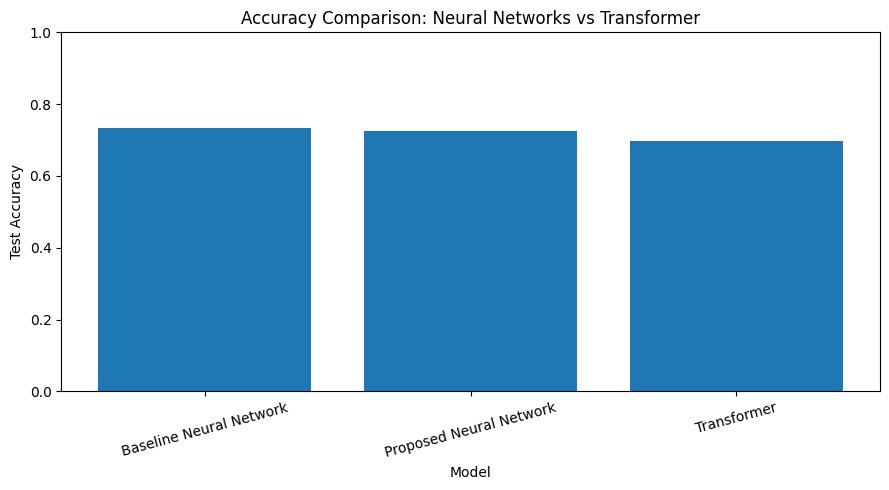

In [55]:

# ============================================
# STEP 6: ACCURACY COMPARISON GRAPH
# ============================================

import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))

plt.bar(
    comparison_df["Model"],
    comparison_df["Accuracy"]
)

plt.title("Accuracy Comparison: Neural Networks vs Transformer")
plt.xlabel("Model")
plt.ylabel("Test Accuracy")
plt.ylim(0, 1)
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()


In [56]:

# ============================================
# STEP 7: SAVE TRANSFORMER COMPARISON RESULTS
# ============================================

import os

os.makedirs("results", exist_ok=True)

comparison_df.to_csv(
    "results/transformer_model_comparison.csv",
    index=False
)

print("Comparison table saved successfully!")
print("File: results/transformer_model_comparison.csv")


Comparison table saved successfully!
File: results/transformer_model_comparison.csv


In [57]:

from google.colab import files

files.download(
    "results/transformer_model_comparison.csv"
)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

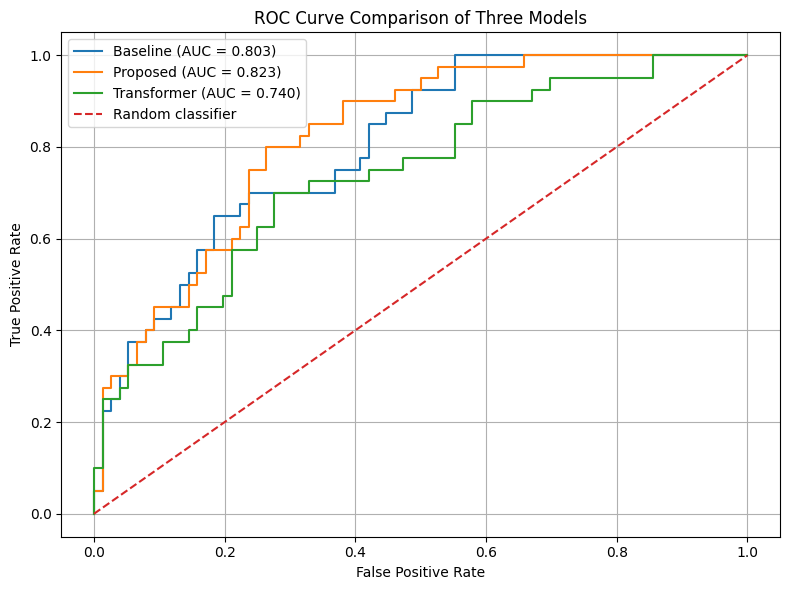

In [58]:

# ============================================
# STEP 9: ROC CURVE COMPARISON
# ============================================

import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, roc_auc_score

# Calculate ROC curves
baseline_fpr, baseline_tpr, _ = roc_curve(
    y_test, baseline_prob
)

proposed_fpr, proposed_tpr, _ = roc_curve(
    y_test, proposed_prob
)

transformer_fpr, transformer_tpr, _ = roc_curve(
    y_test, transformer_prob
)

# Calculate AUC values
baseline_auc_value = roc_auc_score(y_test, baseline_prob)
proposed_auc_value = roc_auc_score(y_test, proposed_prob)
transformer_auc_value = roc_auc_score(y_test, transformer_prob)

# Plot
plt.figure(figsize=(8, 6))

plt.plot(
    baseline_fpr, baseline_tpr,
    label=f"Baseline (AUC = {baseline_auc_value:.3f})"
)

plt.plot(
    proposed_fpr, proposed_tpr,
    label=f"Proposed (AUC = {proposed_auc_value:.3f})"
)

plt.plot(
    transformer_fpr, transformer_tpr,
    label=f"Transformer (AUC = {transformer_auc_value:.3f})"
)

plt.plot([0, 1], [0, 1], linestyle="--", label="Random classifier")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve Comparison of Three Models")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()
